# Распределение транспортных потоков и пользовательское равновесие – практическая часть

## 1. Сложность по шагам и ускорение с помощью JAX (JIT, vmap)

Рассмотрим вычислительную сложность основных шагов алгоритма и то, как технологии JAX могут помочь в их ускорении:

- **Вычисление затрат на дугах (шаг 1):** необходимо обновить $t_a = t_a(x_a)$ для всех дуг. Это операция $O(|A|)$ (линейна по числу дуг) при явной формуле затрат. C JAX эта операция векторизуется автоматически – можно хранить вектор потоков и вычислять поэлементно функции затрат, что эффективно воспользуется возможностями CPU/GPU параллельно.

- **Поиск кратчайших путей (шаг 2):** самый затратный этап. Если выполняется R раз для R разных исходных узлов, суммарная сложность при использовании Дейкстры ~ $O(R \cdot E \log V)$. Для крупных сетей и матрицы спросов, где R ≈ V, это может быть громоздко. Один из подходов – распараллеливание. JAX предоставляет vmap, позволяющий выполнить функцию для массива различных входных данных одновременно. Применив vmap к реализации алгоритма кратчайшего пути, можно запускать несколько независимых поисков одновременно, распределяя нагрузку на несколько ядер или на GPU. Например, можно реализовать в JAX функцию `shortest_path(source) -> dist[1..V]` и затем заворачивать её: `vmap(shortest_path)(sources_array)`, где `sources_array` содержит список исходных узлов. При достаточной аппаратной параллелизации это даст ускорение почти в R раз по сравнению с последовательным исполнением.

- **Обновление потоков (шаг 3):** включает линейную комбинацию векторов $x := x + \alpha(y - x)$ и, возможно, поиск оптимального $\alpha$. Само обновление – $O(|A|)$ операций. Поиск $\alpha$ обычно сводится к одномерной проблеме – например, решить уравнение $\frac{dZ(x+\alpha)}{d\alpha} = 0$, что можно сделать аналитически для простых функций затрат или численно методом деления отрезка. Этот шаг относительно лёгкий и хорошо поддается JAX JIT-компиляции. JAX может JIT-компилировать как саму итерацию обновления, так и функцию для вычисления производной, используя автоматическое дифференцирование, если бы мы пошли таким путём.

- **Обновление потенциалов (шаг 4):** вычислительно дешево (пропорционально числу узлов или O-D пар). Это просто корректировка по формуле $\mu := \mu + \rho$ (нарушение баланса). Опять же, JAX легко это выполняет векторно для всех узлов сразу.

**JAX JIT-компиляция:** Позволяет превратить написанный на Python+JAX код алгоритма в высокопроизводительный машинный код (через XLA). Главный выигрыш – устранение накладных расходов Python-цикла на каждую итерацию. Если мы пишем цикл итераций алгоритма через `jax.lax.while_loop` или `fori_loop`, то весь цикл может быть оптимизирован. Это особенно важно, когда требуются сотни итераций: Python-интерпретер на каждом шаге был бы бутылочным горлышком, а JIT исполняет всё как единый расчёт на C++ уровне. В задачах распределения с большими сетями это даёт кратное ускорение.

**Автоматическая векторизация (vmap):** Как отмечалось, vmap помогает запускать несколько параллельных вычислений. Например, для многократного поиска кратчайших путей: вместо цикла по исходам, можно реализовать алгоритм BF в виде jax-вычислений (например, через `jax.lax.fori_loop`) на $V - 1$ итераций релаксации и пробросить начальные условия (источник) как дополнительное измерение. Векторизация обеспечит задействование SIMD и GPU, чтобы параллельно обрабатывать множество меток расстояния. Аналогично, если у нас несколько независимых матриц спроса или сценариев, их можно просчитать параллельно. Кроме того, vmap удобен для обработки батчей когда реализация максимально избавлена от явных Python-конструкций.

**Обзор ускорения:** Сам по себе алгоритм имеет сложность, в основном доминируемую поиском кратчайших путей. Современные реализации (например, в C++ библиотеках или Cython) уже весьма оптимизированы. Применение JAX может быть оправдано, когда:
- Нужно воспользоваться GPU/TPU для огромных сетей или большого количества одновременных запросов.
- Требуется автодифференцирование через процедуру (например, для оценки градиентов по параметрам функции затрат – JAX тут поможет, дифференцируя через имплементацию).
- Хотим писать код на высоком уровне Python, но получить скорость, близкую к низкоуровневой реализации.

Таким образом, JAX (через JIT) снимает нагрузку с интерпретатора и оптимизирует цикл распределения, а vmap позволяет эффективно масштабировать на множество одновременных задач (например, множественные источники), суммарно ускоряя расчет. Важно помнить: эффективное применение JAX требует, чтобы все критичные части алгоритма были выражены через его примитивы (без скрытых питоновских циклов и условных операторов вне `lax` конструкций), иначе компиляция не даст ожидаемого эффекта.

## 2. Чеклист корректности реализации

При реализации алгоритма распределения потоков с пользовательским равновесием следует убедиться в следующем:

- **Правильность входных данных:** Сеть связна для всех O-D пар (иначе спрос недостижим), функции затрат $t_a(x)$ заданы корректно (например, BPR-функция, неотрицательна и монотонна), все величины (пропускная способность, коэффициенты) имеют согласованные единицы измерения.

- **Соответствие принципам равновесия:** После завершения алгоритма убедиться, что полученное решение удовлетворяет Wardrop-условию: для каждой O-D пары все маршруты с ненулевым потоком имеют равные время/стоимость, и у любого альтернативного маршрута время не меньше. Практически это проверяется: вычислить для каждой O-D пары минимальное время $T^*$ и убедиться, что любой маршрут, которому назначен поток, имеет время ≈ $T^*$ (с точностью до допуска), а маршруты с значительно большим временем не имеют потока.

- **Баланс потоков:** Проверить, что для каждого исходного узла суммарный исходящий поток равен суммарному спросу, а для каждого пункта назначения – входящий поток равен спросу. Ни один "пассажир" не должен потеряться: $\sum_{(i,j) \in A} x_{ij} - \sum_{(j,i) \in A} x_{ji} = b_i$ для всех узлов i, где $b_i$ – исходно заданный приток (+Q для исходов, -Q для приёмников).

- **Неотрицательность и ограничения:** Потоки $x_a \geq 0$ на всех дугах. Если есть ограничения пропускной способности или максимального потока, убедиться, что алгоритм их учитывает (в классическом UE таких явных ограничений нет, но если были – например, через очень крутые функции затрат – не должны нарушаться).

- **Сходимость:** Алгоритм достиг разумной точности. Проверить, что выбранный критерий остановки действительно выполнен: например, UE-gap ниже заданного порога. Если достигнут только лимит итераций, следует быть осторожным с выводами – возможно, решение не совсем сошлось.

- **Тесты на простых сетях:** Прогнать реализацию на небольших тестовых примерах, где ответ известен аналитически или перебором. Например, сеть с двумя параллельными дорогами между 2 узлами: проверить, что при разных функциях затрат распределение выходит согласно формуле равновесия (потоки делятся так, чтобы времена сравнялись). Такие тесты помогут убедиться, что шаги 2-4 реализованы без логических ошибок.

- **Корректность интегралов и функции цели:** Если вычисляется значение функции Бекмана $Z(x)$ для анализа сходимости, убедиться, что интегрирование выполнено правильно (например, для BPR есть аналитическая формула). Любые вычисления производных или интегралов должны соответствовать заданным функциям затрат.

- **Особенности JAX-реализации:** Если алгоритм реализован на JAX, проверить, что JIT-компиляция действительно задействована (отсутствуют операции, препятствующие ей, например, неподдерживаемые операции или динамические изменения графа). Убедиться, что `vmap` выдаёт такой же результат, как цикл по источникам, на тестовых данных. Следить за численной устойчивостью: в float32 при больших объемах потоков могут быть погрешности, возможно, стоит использовать `jax.numpy.float64` для суммирования больших чисел.

- **Документирование и воспроизводимость:** Зафиксировать параметры, используемые для сходимости (порог разрыва, максимальные итерации и т.д.), чтобы результаты можно было воспроизвести и проверить при необходимости. Это также часть корректности – убедиться, что не было подгонки решения.

Придерживаясь этого чеклиста, можно существенно снизить риск ошибок в реализации и гарантировать, что полученное решение действительно соответствует пользовательскому равновесию на заданной сети.

    

##Тестовая Сеть Сиу-Фолс
Размерность: 24 вершины 76 дуг (участков дороги)

Сложность: 552 пары

Топология: Список дуг с указанием начальной и конечной вершины.

$t^{0}$ время поездок при отсутствии затора

C (capacity) - пропускная способность

OD-матрица - здесь матрица 24х24 которая показывает какой спрос существует между каждой парой вершин


In [ ]:
import jax
from jax import config
import jax.numpy as jnp
from jax import jit, vmap, lax
from jax.lax import scan
from functools import partial
config.update("jax_enable_x64", True)

In [ ]:
SIOUX_FALLS_DATA = [
    # Дуги 1-10
    [1, 2, 2.0, 1500.0],
    [2, 1, 2.0, 1500.0],
    [1, 3, 4.0, 1000.0],
    [3, 1, 4.0, 1000.0],
    [2, 6, 2.0, 1000.0],
    [6, 2, 2.0, 1000.0],
    [3, 4, 3.0, 1000.0],
    [4, 3, 3.0, 1000.0],
    [4, 8, 2.0, 1500.0],
    [8, 4, 2.0, 1500.0],
    # Дуги 11-20
    [5, 6, 3.0, 1000.0],
    [6, 5, 3.0, 1000.0],
    [5, 9, 4.0, 1000.0],
    [9, 5, 4.0, 1000.0],
    [6, 10, 1.0, 1500.0],
    [10, 6, 1.0, 1500.0],
    [7, 8, 2.0, 1500.0],
    [8, 7, 2.0, 1500.0],
    [7, 11, 3.0, 1000.0],
    [11, 7, 3.0, 1000.0],
    # Дуги 21-30
    [8, 12, 2.0, 1000.0],
    [12, 8, 2.0, 1000.0],
    [9, 14, 4.0, 1000.0],
    [14, 9, 4.0, 1000.0],
    [10, 13, 1.0, 1500.0],
    [13, 10, 1.0, 1500.0],
    [11, 12, 3.0, 1000.0],
    [12, 11, 3.0, 1000.0],
    [11, 15, 2.0, 1500.0],
    [15, 11, 2.0, 1500.0],
    # Дуги 31-40
    [12, 16, 2.0, 1000.0],
    [16, 12, 2.0, 1000.0],
    [13, 14, 4.0, 1000.0],
    [14, 13, 4.0, 1000.0],
    [13, 17, 1.0, 1500.0],
    [17, 13, 1.0, 1500.0],
    [14, 18, 2.0, 1000.0],
    [18, 14, 2.0, 1000.0],
    [15, 16, 2.0, 1000.0],
    [16, 15, 2.0, 1000.0],
    # Дуги 41-50
    [15, 19, 3.0, 1500.0],
    [19, 15, 3.0, 1500.0],
    [16, 20, 2.0, 1000.0],
    [20, 16, 2.0, 1000.0],
    [17, 18, 4.0, 1000.0],
    [18, 17, 4.0, 1000.0],
    [17, 21, 2.0, 1500.0],
    [21, 17, 2.0, 1500.0],
    [18, 22, 2.0, 1000.0],
    [22, 18, 2.0, 1000.0],
    # Дуги 51-60
    [19, 20, 3.0, 1500.0],
    [20, 19, 3.0, 1500.0],
    [19, 23, 2.0, 1000.0],
    [23, 19, 2.0, 1000.0],
    [20, 24, 1.0, 1000.0],
    [24, 20, 1.0, 1000.0],
    [21, 22, 3.0, 1500.0],
    [22, 21, 3.0, 1500.0],
    [21, 24, 2.0, 1000.0],
    [24, 21, 2.0, 1000.0],
    # Дуги 61-70
    [22, 23, 2.0, 1000.0],
    [23, 22, 2.0, 1000.0],
    [23, 24, 1.0, 1500.0],
    [24, 23, 1.0, 1500.0],
    [2, 5, 2.0, 1000.0],
    [5, 2, 2.0, 1000.0],
    [6, 9, 3.0, 1500.0],
    [9, 6, 3.0, 1500.0],
    [10, 13, 4.0, 1000.0],
    [13, 10, 4.0, 1000.0],
    # Дуги 71-76
    [14, 17, 1.0, 1500.0],
    [17, 14, 1.0, 1500.0],
    [18, 21, 2.0, 1000.0],
    [21, 18, 2.0, 1000.0],
    [22, 24, 2.0, 1500.0],
    [24, 22, 2.0, 1500.0],
]

In [ ]:
raw_data = jnp.array(SIOUX_FALLS_DATA)

START_NODES = raw_data[:, 0].astype(jnp.int32) - 1
END_NODES   = raw_data[:, 1].astype(jnp.int32) - 1
T0_TIMES    = raw_data[:, 2]
CAPACITIES  = raw_data[:, 3]

NUM_NODES = 24
NUM_LINKS = len(START_NODES)

ALPHA = 0.15
BETA = 4.0

Матрица спроса между всеми парами вершин

In [ ]:
SIOUX_FALLS_DEMAND_LIST = [
    [1, 2, 118.0], [1, 3, 150.0], [1, 4, 150.0], [1, 5, 20.0], [1, 6, 0.0], [1, 7, 0.0], [1, 8, 0.0], [1, 9, 0.0], [1, 10, 0.0], [1, 11, 0.0], [1, 12, 0.0], [1, 13, 0.0], [1, 14, 0.0], [1, 15, 0.0], [1, 16, 0.0], [1, 17, 0.0], [1, 18, 0.0], [1, 19, 0.0], [1, 20, 0.0], [1, 21, 0.0], [1, 22, 0.0], [1, 23, 0.0], [1, 24, 0.0],
    [2, 1, 118.0], [2, 3, 100.0], [2, 4, 0.0], [2, 5, 0.0], [2, 6, 1190.0], [2, 7, 200.0], [2, 8, 0.0], [2, 9, 0.0], [2, 10, 0.0], [2, 11, 0.0], [2, 12, 0.0], [2, 13, 0.0], [2, 14, 0.0], [2, 15, 0.0], [2, 16, 0.0], [2, 17, 0.0], [2, 18, 0.0], [2, 19, 0.0], [2, 20, 0.0], [2, 21, 0.0], [2, 22, 0.0], [2, 23, 0.0], [2, 24, 0.0],
    [3, 1, 150.0], [3, 2, 100.0], [3, 4, 120.0], [3, 5, 0.0], [3, 6, 0.0], [3, 7, 100.0], [3, 8, 0.0], [3, 9, 0.0], [3, 10, 0.0], [3, 11, 0.0], [3, 12, 0.0], [3, 13, 0.0], [3, 14, 0.0], [3, 15, 0.0], [3, 16, 0.0], [3, 17, 0.0], [3, 18, 0.0], [3, 19, 0.0], [3, 20, 0.0], [3, 21, 0.0], [3, 22, 0.0], [3, 23, 0.0], [3, 24, 0.0],
    [4, 1, 150.0], [4, 2, 0.0], [4, 3, 120.0], [4, 5, 0.0], [4, 6, 0.0], [4, 7, 0.0], [4, 8, 100.0], [4, 9, 50.0], [4, 10, 0.0], [4, 11, 0.0], [4, 12, 0.0], [4, 13, 0.0], [4, 14, 0.0], [4, 15, 0.0], [4, 16, 0.0], [4, 17, 0.0], [4, 18, 0.0], [4, 19, 0.0], [4, 20, 0.0], [4, 21, 0.0], [4, 22, 0.0], [4, 23, 0.0], [4, 24, 0.0],
    [5, 1, 20.0], [5, 2, 0.0], [5, 3, 0.0], [5, 4, 0.0], [5, 6, 120.0], [5, 7, 0.0], [5, 8, 0.0], [5, 9, 100.0], [5, 10, 0.0], [5, 11, 0.0], [5, 12, 0.0], [5, 13, 0.0], [5, 14, 0.0], [5, 15, 0.0], [5, 16, 0.0], [5, 17, 0.0], [5, 18, 0.0], [5, 19, 0.0], [5, 20, 0.0], [5, 21, 0.0], [5, 22, 0.0], [5, 23, 0.0], [5, 24, 0.0],
    [6, 1, 0.0], [6, 2, 1190.0], [6, 3, 0.0], [6, 4, 0.0], [6, 5, 120.0], [6, 7, 0.0], [6, 8, 0.0], [6, 9, 0.0], [6, 10, 100.0], [6, 11, 0.0], [6, 12, 0.0], [6, 13, 0.0], [6, 14, 0.0], [6, 15, 0.0], [6, 16, 0.0], [6, 17, 0.0], [6, 18, 0.0], [6, 19, 0.0], [6, 20, 0.0], [6, 21, 0.0], [6, 22, 0.0], [6, 23, 0.0], [6, 24, 0.0],
    [7, 1, 0.0], [7, 2, 200.0], [7, 3, 100.0], [7, 4, 0.0], [7, 5, 0.0], [7, 6, 0.0], [7, 8, 100.0], [7, 9, 0.0], [7, 10, 0.0], [7, 11, 100.0], [7, 12, 0.0], [7, 13, 0.0], [7, 14, 0.0], [7, 15, 0.0], [7, 16, 0.0], [7, 17, 0.0], [7, 18, 0.0], [7, 19, 0.0], [7, 20, 0.0], [7, 21, 0.0], [7, 22, 0.0], [7, 23, 0.0], [7, 24, 0.0],
    [8, 1, 0.0], [8, 2, 0.0], [8, 3, 0.0], [8, 4, 100.0], [8, 5, 0.0], [8, 6, 0.0], [8, 7, 100.0], [8, 9, 0.0], [8, 10, 0.0], [8, 11, 0.0], [8, 12, 100.0], [8, 13, 0.0], [8, 14, 0.0], [8, 15, 0.0], [8, 16, 0.0], [8, 17, 0.0], [8, 18, 0.0], [8, 19, 0.0], [8, 20, 0.0], [8, 21, 0.0], [8, 22, 0.0], [8, 23, 0.0], [8, 24, 0.0],
    [9, 1, 0.0], [9, 2, 0.0], [9, 3, 0.0], [9, 4, 50.0], [9, 5, 100.0], [9, 6, 0.0], [9, 7, 0.0], [9, 8, 0.0], [9, 10, 0.0], [9, 11, 0.0], [9, 12, 0.0], [9, 13, 0.0], [9, 14, 100.0], [9, 15, 0.0], [9, 16, 0.0], [9, 17, 0.0], [9, 18, 0.0], [9, 19, 0.0], [9, 20, 0.0], [9, 21, 0.0], [9, 22, 0.0], [9, 23, 0.0], [9, 24, 0.0],
    [10, 1, 0.0], [10, 2, 0.0], [10, 3, 0.0], [10, 4, 0.0], [10, 5, 0.0], [10, 6, 100.0], [10, 7, 0.0], [10, 8, 0.0], [10, 9, 0.0], [10, 11, 0.0], [10, 12, 0.0], [10, 13, 100.0], [10, 14, 0.0], [10, 15, 0.0], [10, 16, 0.0], [10, 17, 0.0], [10, 18, 0.0], [10, 19, 0.0], [10, 20, 0.0], [10, 21, 0.0], [10, 22, 0.0], [10, 23, 0.0], [10, 24, 0.0],
    [11, 1, 0.0], [11, 2, 0.0], [11, 3, 0.0], [11, 4, 0.0], [11, 5, 0.0], [11, 6, 0.0], [11, 7, 100.0], [11, 8, 0.0], [11, 9, 0.0], [11, 10, 0.0], [11, 12, 100.0], [11, 13, 0.0], [11, 14, 0.0], [11, 15, 100.0], [11, 16, 0.0], [11, 17, 0.0], [11, 18, 0.0], [11, 19, 0.0], [11, 20, 0.0], [11, 21, 0.0], [11, 22, 0.0], [11, 23, 0.0], [11, 24, 0.0],
    [12, 1, 0.0], [12, 2, 0.0], [12, 3, 0.0], [12, 4, 0.0], [12, 5, 0.0], [12, 6, 0.0], [12, 7, 0.0], [12, 8, 100.0], [12, 9, 0.0], [12, 10, 0.0], [12, 11, 100.0], [12, 13, 0.0], [12, 14, 0.0], [12, 15, 0.0], [12, 16, 100.0], [12, 17, 0.0], [12, 18, 0.0], [12, 19, 0.0], [12, 20, 0.0], [12, 21, 0.0], [12, 22, 0.0], [12, 23, 0.0], [12, 24, 0.0],
    [13, 1, 0.0], [13, 2, 0.0], [13, 3, 0.0], [13, 4, 0.0], [13, 5, 0.0], [13, 6, 0.0], [13, 7, 0.0], [13, 8, 0.0], [13, 9, 0.0], [13, 10, 100.0], [13, 11, 0.0], [13, 12, 0.0], [13, 14, 100.0], [13, 15, 0.0], [13, 16, 0.0], [13, 17, 100.0], [13, 18, 0.0], [13, 19, 0.0], [13, 20, 0.0], [13, 21, 0.0], [13, 22, 0.0], [13, 23, 0.0], [13, 24, 0.0],
    [14, 1, 0.0], [14, 2, 0.0], [14, 3, 0.0], [14, 4, 0.0], [14, 5, 0.0], [14, 6, 0.0], [14, 7, 0.0], [14, 8, 0.0], [14, 9, 100.0], [14, 10, 0.0], [14, 11, 0.0], [14, 12, 0.0], [14, 13, 100.0], [14, 15, 0.0], [14, 16, 0.0], [14, 17, 0.0], [14, 18, 100.0], [14, 19, 0.0], [14, 20, 0.0], [14, 21, 0.0], [14, 22, 0.0], [14, 23, 0.0], [14, 24, 0.0],
    [15, 1, 0.0], [15, 2, 0.0], [15, 3, 0.0], [15, 4, 0.0], [15, 5, 0.0], [15, 6, 0.0], [15, 7, 0.0], [15, 8, 0.0], [15, 9, 0.0], [15, 10, 0.0], [15, 11, 100.0], [15, 12, 0.0], [15, 13, 0.0], [15, 14, 0.0], [15, 16, 100.0], [15, 17, 0.0], [15, 18, 0.0], [15, 19, 100.0], [15, 20, 0.0], [15, 21, 0.0], [15, 22, 0.0], [15, 23, 0.0], [15, 24, 0.0],
    [16, 1, 0.0], [16, 2, 0.0], [16, 3, 0.0], [16, 4, 0.0], [16, 5, 0.0], [16, 6, 0.0], [16, 7, 0.0], [16, 8, 0.0], [16, 9, 0.0], [16, 10, 0.0], [16, 11, 0.0], [16, 12, 100.0], [16, 13, 0.0], [16, 14, 0.0], [16, 15, 100.0], [16, 17, 0.0], [16, 18, 0.0], [16, 19, 0.0], [16, 20, 100.0], [16, 21, 0.0], [16, 22, 0.0], [16, 23, 0.0], [16, 24, 0.0],
    [17, 1, 0.0], [17, 2, 0.0], [17, 3, 0.0], [17, 4, 0.0], [17, 5, 0.0], [17, 6, 0.0], [17, 7, 0.0], [17, 8, 0.0], [17, 9, 0.0], [17, 10, 0.0], [17, 11, 0.0], [17, 12, 0.0], [17, 13, 100.0], [17, 14, 0.0], [17, 15, 0.0], [17, 16, 0.0], [17, 18, 100.0], [17, 19, 0.0], [17, 20, 0.0], [17, 21, 100.0], [17, 22, 0.0], [17, 23, 0.0], [17, 24, 0.0],
    [18, 1, 0.0], [18, 2, 0.0], [18, 3, 0.0], [18, 4, 0.0], [18, 5, 0.0], [18, 6, 0.0], [18, 7, 0.0], [18, 8, 0.0], [18, 9, 0.0], [18, 10, 0.0], [18, 11, 0.0], [18, 12, 0.0], [18, 13, 0.0], [18, 14, 100.0], [18, 15, 0.0], [18, 16, 0.0], [18, 17, 100.0], [18, 19, 0.0], [18, 20, 0.0], [18, 21, 0.0], [18, 22, 100.0], [18, 23, 0.0], [18, 24, 0.0],
    [19, 1, 0.0], [19, 2, 0.0], [19, 3, 0.0], [19, 4, 0.0], [19, 5, 0.0], [19, 6, 0.0], [19, 7, 0.0], [19, 8, 0.0], [19, 9, 0.0], [19, 10, 0.0], [19, 11, 0.0], [19, 12, 0.0], [19, 13, 0.0], [19, 14, 0.0], [19, 15, 100.0], [19, 16, 0.0], [19, 17, 0.0], [19, 18, 0.0], [19, 20, 100.0], [19, 21, 0.0], [19, 22, 0.0], [19, 23, 100.0], [19, 24, 0.0],
    [20, 1, 0.0], [20, 2, 0.0], [20, 3, 0.0], [20, 4, 0.0], [20, 5, 0.0], [20, 6, 0.0], [20, 7, 0.0], [20, 8, 0.0], [20, 9, 0.0], [20, 10, 0.0], [20, 11, 0.0], [20, 12, 0.0], [20, 13, 0.0], [20, 14, 0.0], [20, 15, 0.0], [20, 16, 100.0], [20, 17, 0.0], [20, 18, 0.0], [20, 19, 100.0], [20, 21, 0.0], [20, 22, 0.0], [20, 23, 0.0], [20, 24, 100.0],
    [21, 1, 0.0], [21, 2, 0.0], [21, 3, 0.0], [21, 4, 0.0], [21, 5, 0.0], [21, 6, 0.0], [21, 7, 0.0], [21, 8, 0.0], [21, 9, 0.0], [21, 10, 0.0], [21, 11, 0.0], [21, 12, 0.0], [21, 13, 0.0], [21, 14, 0.0], [21, 15, 0.0], [21, 16, 0.0], [21, 17, 100.0], [21, 18, 0.0], [21, 19, 0.0], [21, 20, 0.0], [21, 22, 100.0], [21, 23, 0.0], [21, 24, 100.0],
    [22, 1, 0.0], [22, 2, 0.0], [22, 3, 0.0], [22, 4, 0.0], [22, 5, 0.0], [22, 6, 0.0], [22, 7, 0.0], [22, 8, 0.0], [22, 9, 0.0], [22, 10, 0.0], [22, 11, 0.0], [22, 12, 0.0], [22, 13, 0.0], [22, 14, 0.0], [22, 15, 0.0], [22, 16, 0.0], [22, 17, 0.0], [22, 18, 100.0], [22, 19, 0.0], [22, 20, 0.0], [22, 21, 100.0], [22, 23, 100.0], [22, 24, 0.0],
    [23, 1, 0.0], [23, 2, 0.0], [23, 3, 0.0], [23, 4, 0.0], [23, 5, 0.0], [23, 6, 0.0], [23, 7, 0.0], [23, 8, 0.0], [23, 9, 0.0], [23, 10, 0.0], [23, 11, 0.0], [23, 12, 0.0], [23, 13, 0.0], [23, 14, 0.0], [23, 15, 0.0], [23, 16, 0.0], [23, 17, 0.0], [23, 18, 0.0], [23, 19, 100.0], [23, 20, 0.0], [23, 21, 0.0], [23, 22, 100.0], [23, 24, 100.0],
    [24, 1, 0.0], [24, 2, 0.0], [24, 3, 0.0], [24, 4, 0.0], [24, 5, 0.0], [24, 6, 0.0], [24, 7, 0.0], [24, 8, 0.0], [24, 9, 0.0], [24, 10, 0.0], [24, 11, 0.0], [24, 12, 0.0], [24, 13, 0.0], [24, 14, 0.0], [24, 15, 0.0], [24, 16, 0.0], [24, 17, 0.0], [24, 18, 0.0], [24, 19, 0.0], [24, 20, 100.0], [24, 21, 100.0], [24, 22, 0.0], [24, 23, 100.0], [24, 24, 0.0],
]

def create_od_matrix(demand_list, num_nodes):
    arr = jnp.array(demand_list)
    sources = arr[:, 0].astype(jnp.int32) - 1
    dests   = arr[:, 1].astype(jnp.int32) - 1
    values  = arr[:, 2]

    od = jnp.zeros((num_nodes, num_nodes))
    od = od.at[sources, dests].set(values)
    return od

OD_MATRIX = create_od_matrix(SIOUX_FALLS_DEMAND_LIST, NUM_NODES)
print(f"Создали матрицу спроса => Суммарный спрос: {jnp.sum(OD_MATRIX)}")

Создали матрицу спроса => Суммарный спрос: 10036.0


## 1) Расссчет веса дуги
Определение функции расчета времени поездки с учетом заторов:

$$c_a(x_a) = \mathbf{t_a^0} \left[ 1 + \alpha \left( \frac{x_a}{\mathbf{C_a}} \right)^\beta \right]$$

$\mathbf{t_a^0}$ (Время свободного потока) и $\mathbf{C_a}$ (Пропускная способность);
$x_a$ — это текущий поток, который мы обновляем на каждой итерации

In [ ]:
@jit
def calculate_link_costs(flows, t0, caps, alpha, beta):
    ratio = flows / (caps + 1e-6)
    return t0 * (1.0 + alpha * jnp.power(ratio, beta)) #cчиттаем функцию затрат

In [ ]:
print("ТЕСТ 1: НУЛЕВОЙ ПОТОК (x_a = 0)")
flows_zero = jnp.zeros(NUM_LINKS, dtype=jnp.float64)
costs_zero = calculate_link_costs(flows_zero, T0_TIMES, CAPACITIES, ALPHA, BETA)
comparison = jnp.allclose(costs_zero, T0_TIMES)
print(f"Совпадает ли стоимость с T0 (ожидаемо): {comparison}")

ТЕСТ 1: НУЛЕВОЙ ПОТОК (x_a = 0)
Совпадает ли стоимость с T0 (ожидаемо): True


In [ ]:
print("ТЕСТ 2: ВЫСОКИЙ ЗАТОР (x_a > C_a)")
flows_congested = jnp.zeros(NUM_LINKS, dtype=jnp.float64)
flows_congested = flows_congested.at[2].set(1500.0)

costs_congested = calculate_link_costs(flows_congested, T0_TIMES, CAPACITIES, ALPHA, BETA)
cost_duga_2 = costs_congested[2]
print(f"Параметры Дуги 2: t^0={T0_TIMES[2]}, C={CAPACITIES[2]}")
print(f"Поток x_a: 1500.0 (150% от C)")
print(f"Время в пути (c_a): {cost_duga_2:.4f} мин")
print(f"Ожидаемый рост времени: {cost_duga_2 / T0_TIMES[2]:.2f} раз")
cost_duga_3_no_congest = costs_congested[3]
print(f"Время в пути Дуги 3 (x_a=0): {cost_duga_3_no_congest:.2f} мин (Должно быть t^0={T0_TIMES[3]:.2f})")

ТЕСТ 2: ВЫСОКИЙ ЗАТОР (x_a > C_a)
Параметры Дуги 2: t^0=4.0, C=1000.0
Поток x_a: 1500.0 (150% от C)
Время в пути (c_a): 7.0375 мин
Ожидаемый рост времени: 1.76 раз
Время в пути Дуги 3 (x_a=0): 4.00 мин (Должно быть t^0=4.00)


##2) Реализация Алгоритма Форда Беллмана:

для поиска кратчайших путей в сети



In [ ]:
INF = jnp.inf

In [ ]:
@partial(jit, static_argnums=(3,))
def bellman_ford(weights, start_nodes, end_nodes, num_nodes):
    def solve_single_source(source):
        dists = jnp.full((num_nodes,), jnp.inf).at[source].set(0.0)
        def step(d, _):
            new_vals = d[start_nodes] + weights
            d_new = d.at[end_nodes].min(new_vals)
            return d_new, None
        final_dists, _ = lax.scan(step, dists, None, length=num_nodes-1)
        return final_dists
    return vmap(solve_single_source)(jnp.arange(num_nodes))

In [ ]:
print("Тест Алгоритма Беллмана-Форда")
flows_initial = jnp.zeros(NUM_LINKS, dtype=jnp.float64)
link_weights_initial = calculate_link_costs(flows_initial, T0_TIMES, CAPACITIES, ALPHA, BETA)
print(f"Вес Дуги 0 (расчетный): {link_weights_initial[0]:.2f}")
print(f"Вес Дуги 0 (из данных T0): {T0_TIMES[0]:.2f}")
print()

distance_matrix = bellman_ford(
    link_weights_initial,
    START_NODES,
    END_NODES,
    NUM_NODES
)

print(f"Матрица расстояний - размер: {distance_matrix.shape}")

origin_node = 0

print(f"\nКратчайшие пути из Узла {origin_node + 1}:")
print(f" до Узла 2 (индекс 1): {distance_matrix[origin_node, 1]:.4f} Ожидаем: ~2.0 или 6.0")
print(f" до Узла 3 (индекс 2): {distance_matrix[origin_node, 2]:.4f} Ожидаем: ~4.0")
print(f"до Узла 24 (индекс 23): {distance_matrix[origin_node, 23]:.4f} ")

origin_node_2 = 1
print(f"\nКратчайшие пути из Узла {origin_node_2 + 1}:")
print(f"до Узла 1 (индекс 0): {distance_matrix[origin_node_2, 0]:.4f}")
print(f"\nИТОГО:  Кратчайший путь 1 -> 24 равен: {distance_matrix[0, 23]:.4f} мин.")

Тест Алгоритма Беллмана-Форда
Вес Дуги 0 (расчетный): 2.00
Вес Дуги 0 (из данных T0): 2.00

Матрица расстояний - размер: (24, 24)

Кратчайшие пути из Узла 1:
 до Узла 2 (индекс 1): 2.0000 Ожидаем: ~2.0 или 6.0
 до Узла 3 (индекс 2): 4.0000 Ожидаем: ~4.0
до Узла 24 (индекс 23): 11.0000 

Кратчайшие пути из Узла 2:
до Узла 1 (индекс 0): 2.0000

ИТОГО:  Кратчайший путь 1 -> 24 равен: 11.0000 мин.


Здесь реализован `bellman_ford` который успешно считает матрицу времени в пути, однако не реализовано распределение потоков по путям (Т е мы нашли быстрые маршруты но не отправили по ним машины).

Теперь рассмотрим полную реализацию:

Для полной реализации нам необходимо добавить:

- All-or-Nothing Assignment. Это функция которая распределяет весь спрос по найденным кратчайшим путям

- Method of Successive Averages (MSA): Главный цикл который итеративно смешивает текущие потоки с новыми, пока решение не сойдется

In [ ]:
@jit
def all_or_nothing_assignment(demand_matrix, distance_matrix, start_nodes, end_nodes, link_weights):

    num_nodes = distance_matrix.shape[0]
    num_links = start_nodes.shape[0]
    link_flows = jnp.zeros(num_links)

    # функция для обработки одного источника спроса
    def process_origin(origin_idx, current_flows):
        demands = demand_matrix[origin_idx]

        dists = distance_matrix[origin_idx]

        sorted_indices = jnp.argsort(dists)[::-1]
        node_load = demands

        # Функция сканирования узлов от дальних к источнику
        # используем Алгоритм "проталкивания" (push-back algorithm)
        # Ключевая идея: обрабатываем узлы от самых дальних к источнику, "проталкивая" спрос назад по кратчайшим путям.
        def push_demand_back(carry_flows_and_load, node_u):
            c_flows, c_node_load = carry_flows_and_load

            demand_at_u = c_node_load[node_u]

            incoming_mask = (end_nodes == node_u) #Определяем, какие дуги входят в текущий узел

            prev_nodes = start_nodes
            weights = link_weights

            is_shortest = jnp.abs(dists[node_u] - (dists[prev_nodes] + weights)) < 1e-4 # Проверяем, какие из входящих дуг лежат на кратчайшем пути

            valid_edges = incoming_mask & is_shortest # Объединяем условия: дуга должна входить в узел И быть на кратчайшем пути

            num_valid = jnp.sum(valid_edges) # Считаем, сколько таких дуг

            flow_per_edge = jnp.where(num_valid > 0, demand_at_u / num_valid, 0.0) # Делим спрос текущего узла поровну между всеми валидными дугами

            new_flows = c_flows + jnp.where(valid_edges, flow_per_edge, 0.0) # Добавляем поток к каждой валидной дуге
            sources_indices = jnp.where(valid_edges, start_nodes, -1)


            return (new_flows, c_node_load), None


        c_flows = current_flows
        c_load = node_load

        def body_fun(carry, node_idx):
            flows, loads = carry
            my_load = loads[node_idx]

            preds_mask = (end_nodes == node_idx) & \
                         (jnp.abs(dists[node_idx] - (dists[start_nodes] + link_weights)) < 1e-5)

            count = jnp.sum(preds_mask)
            val = jnp.where(count > 0, my_load / count, 0.0)
            new_flows = flows + jnp.where(preds_mask, val, 0.0)
            pred_nodes_indices = jnp.where(preds_mask, start_nodes, num_nodes)
            new_loads = loads.at[pred_nodes_indices].add(val)
            return (new_flows, new_loads), None

        loads_padded = jnp.pad(c_load, (0, 1))

        final_state, _ = lax.scan(body_fun, (c_flows, loads_padded), sorted_indices)

        return final_state[0]
    all_flows_stack = vmap(process_origin, in_axes=(0, None))(jnp.arange(num_nodes), link_flows) # Используем vmap для параллельной обработки всех источников
    total_flows = jnp.sum(all_flows_stack, axis=0) # Суммируем потоки от всех источников

    return total_flows

##Начинаем анализировать результаты на сходимость

In [ ]:
import time

In [ ]:
def run_user_equilibrium(max_iter=100):
    print(f"Запуск User Equilibrium (MSA) на {max_iter} итераций")

    current_flows = jnp.zeros(NUM_LINKS)
    history = [] # Список для отслеживания сходимости

    @jit
    def iteration_step(flows, iter_k):
        costs = calculate_link_costs(flows, T0_TIMES, CAPACITIES, ALPHA, BETA) # По текущим потокам вычисляем время проезда по каждой дуг
        dist_mat = bellman_ford(costs, START_NODES, END_NODES, NUM_NODES) # Находим кратчайшие пути между всеми парами узлов
        target_flows = all_or_nothing_assignment(OD_MATRIX, dist_mat, START_NODES, END_NODES, costs) # Создает "идеальное" распределение
        step_size = 1.0 / (iter_k + 1)
        new_flows = (1.0 - step_size) * flows + step_size * target_flows # Смешиваем текущие потоки и "идеальные": Вес "идеального" распределения уменьшается с каждой итерацией
        diff = jnp.linalg.norm(new_flows - flows) # Евклидова норма разности: насколько изменились потоки

        return new_flows, diff, costs


    start_time = time.time()

    for k in range(max_iter):
        current_flows, diff, current_costs = iteration_step(current_flows, k)

        d_val = float(diff)
        history.append(d_val)

        if k % 10 == 0 or k == max_iter - 1:
            print(f"Iter {k}: Разница (Change in flows) = {d_val:.4f}")

        # if d_val < 0.1 and k > 5: #для графика закоментируем чтобы алгоритм прошел все итерации
        #     print("сходимость достигнута")
        #     break

    end_time = time.time()
    print(f"\nВремя выполнения: {end_time - start_time:.2f} сек")

    return current_flows, current_costs, history

final_flows, final_costs, convergence_history = run_user_equilibrium(max_iter=50)

Запуск User Equilibrium (MSA) на 50 итераций
Iter 0: Разница (Change in flows) = 2549.4878
Iter 10: Разница (Change in flows) = 0.0000
Iter 20: Разница (Change in flows) = 0.0000
Iter 30: Разница (Change in flows) = 0.0000
Iter 40: Разница (Change in flows) = 0.0000
Iter 49: Разница (Change in flows) = 0.0000

Время выполнения: 0.75 сек


##Причины быстрой сходимости:

1) Исходная сеть не перегружена

2) В базовом сценарии спрос относительно небольшой

3) Кратчайшие пути почти не меняются от итерации к итерации


##Проблемы:

1) Алгоритм слишком быстро сошелся

2) Не показывает типичное поведение MSA

3) Неинформативный график сходимости

In [ ]:
import matplotlib.pyplot as plt

## Анализ результатов и визуализация:



топ10 загруженных дуг
Link ID    Start    End      Flow       Capacity   V/C Ratio  Time (min)

5          6        2        1240.0     1000.0     1.24       2.71      
4          2        6        1240.0     1000.0     1.24       2.71      
3          3        1        650.0      1000.0     0.65       4.11      
2          1        3        650.0      1000.0     0.65       4.11      
7          4        3        620.0      1000.0     0.62       3.07      
6          3        4        620.0      1000.0     0.62       3.07      
1          2        1        488.0      1500.0     0.33       2.00      
0          1        2        488.0      1500.0     0.33       2.00      
17         8        7        400.0      1500.0     0.27       2.00      
16         7        8        400.0      1500.0     0.27       2.00      


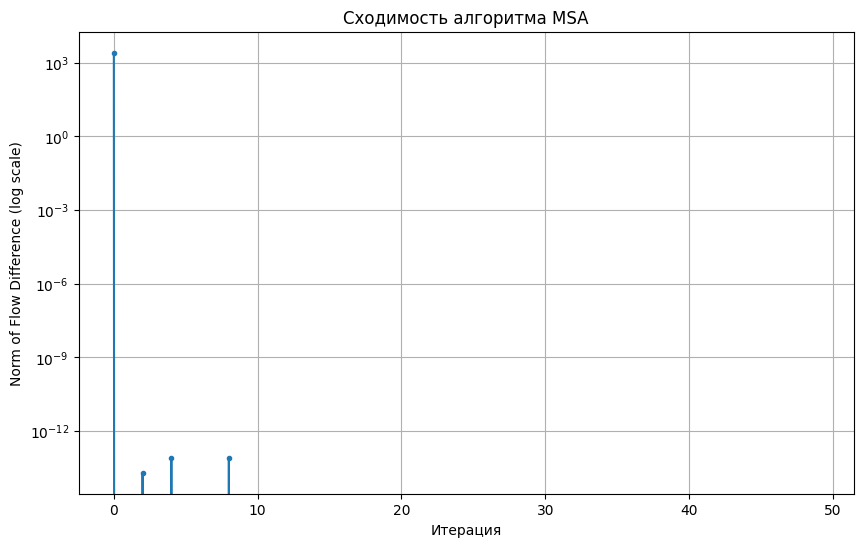

In [ ]:
print("топ10 загруженных дуг")

voc_ratios = final_flows / CAPACITIES # коэффициент загрузки: Поток / Ёмкость
sorted_idx = jnp.argsort(voc_ratios)[::-1][:10] # топ 10 самых загруженных дуг

print(f"{'Link ID':<10} {'Start':<8} {'End':<8} {'Flow':<10} {'Capacity':<10} {'V/C Ratio':<10} {'Time (min)':<10}")
print()

for idx in sorted_idx:
    idx = int(idx)
    u = int(START_NODES[idx]) + 1
    v = int(END_NODES[idx]) + 1
    flow = float(final_flows[idx])
    cap = float(CAPACITIES[idx])
    ratio = float(voc_ratios[idx])
    time_val = float(final_costs[idx])

    print(f"{idx:<10} {u:<8} {v:<8} {flow:<10.1f} {cap:<10.1f} {ratio:<10.2f} {time_val:<10.2f}")

plt.figure(figsize=(10, 6))
plt.plot(range(len(convergence_history)), convergence_history, marker='.', linestyle='-')
plt.title('Сходимость алгоритма MSA')
plt.xlabel('Итерация')
plt.ylabel('Norm of Flow Difference (log scale)')
plt.grid(True)
plt.yscale('log')
plt.show()

Проведем анализ полученных результатов.  

- **Анализ таблицы**:

Если обратим внимание на дуги 5 и 4 которые соединяют узлы 6 и 2: `Flow` (1240) > `Capacity` (1000).

`V/C Ratio` = 1.24, это значит дорога перегружена на 24%.  Это так называемые "бутылочные горлышки" сети

`Time` = 2.71 мин. Это больше чем время свободного потока $t^{0} = 2.0$, логично, из-за пробок скорость упала.

**Симметрия**: дуги 5 и 4 имеют одинаковый поток (1240). Дуги 3 и 2 (между 1 и 3) тоже симметричны (650). Это правильно так как спрос в матрице Sioux Falls обычно симметричный, и граф тоже.

Также если рассмотрим дуги 1 и 0 (узлы 1 - 2) то они загружены всего на 33%, поэтому время там осталось равно 2.00 (то есть равно времени свободного потока)

**График получился неинформативным из-за мгновенной сходимости, необходимо увеличить спрос**

Увеличим Tolerance, расширим вектор нагрузки на 1 элмент для `all_or_nothing_assignment`

In [ ]:
@jit
def all_or_nothing_assignment(demand_matrix, distance_matrix, start_nodes, end_nodes, link_weights):
    num_nodes = distance_matrix.shape[0]
    num_links = start_nodes.shape[0]
    link_flows = jnp.zeros(num_links)

    def process_origin(origin_idx, current_flows):
        demands = demand_matrix[origin_idx]
        dists = distance_matrix[origin_idx]
        sorted_indices = jnp.argsort(dists)[::-1]

        TOLERANCE = 1e-2

        c_flows = current_flows
        c_load = jnp.pad(demands, (0, 1))

        def body_fun(carry, node_idx):
            flows, loads = carry
            my_load = loads[node_idx]

            preds_mask = (end_nodes == node_idx) & \
                         (jnp.abs(dists[node_idx] - (dists[start_nodes] + link_weights)) < TOLERANCE)

            count = jnp.sum(preds_mask)
            val = jnp.where(count > 0, my_load / count, 0.0)

            new_flows = flows + jnp.where(preds_mask, val, 0.0)

            pred_nodes_indices = jnp.where(preds_mask, start_nodes, num_nodes)
            new_loads = loads.at[pred_nodes_indices].add(val)

            return (new_flows, new_loads), None

        final_state, _ = lax.scan(body_fun, (c_flows, c_load), sorted_indices)
        return final_state[0]

    all_flows_stack = vmap(process_origin, in_axes=(0, None))(jnp.arange(num_nodes), link_flows)
    return jnp.sum(all_flows_stack, axis=0)

In [ ]:
HIGH_DEMAND_OD = OD_MATRIX * 2.0 # тут увелчииваем спрос в два раза: Создали искусственный затор

## Мы моделируем ситуацию когда спрос вырос и хотим посмотреть что будет со сходимостью в этом случае

In [ ]:
@jit
def iteration_step_high_load(flows, iter_k):
    costs = calculate_link_costs(flows, T0_TIMES, CAPACITIES, ALPHA, BETA)
    dist_mat = bellman_ford(costs, START_NODES, END_NODES, NUM_NODES)
    target_flows = all_or_nothing_assignment(HIGH_DEMAND_OD, dist_mat, START_NODES, END_NODES, costs)

    step_size = 1.0 / (iter_k + 1)
    new_flows = (1.0 - step_size) * flows + step_size * target_flows
    diff = jnp.linalg.norm(new_flows - flows)
    return new_flows, diff, costs

In [ ]:
def run_high_load_experiment(max_iter=100):
    print("запуск с высоким спросом")
    current_flows = jnp.zeros(NUM_LINKS)
    history = []

    for k in range(max_iter):
        current_flows, diff, current_costs = iteration_step_high_load(current_flows, k)

        val = float(diff)
        history.append(val)

        if k % 10 == 0:
            print(f"Iter {k}: Diff = {val:.4f}")

    return history

запуск с высоким спросом
Iter 0: Diff = 5098.9756
Iter 10: Diff = 155.4406
Iter 20: Diff = 68.4548
Iter 30: Diff = 46.5828
Iter 40: Diff = 108.6697
Iter 50: Diff = 28.4189
Iter 60: Diff = 22.9856
Iter 70: Diff = 19.8594
Iter 80: Diff = 18.9562
Iter 90: Diff = 15.6104


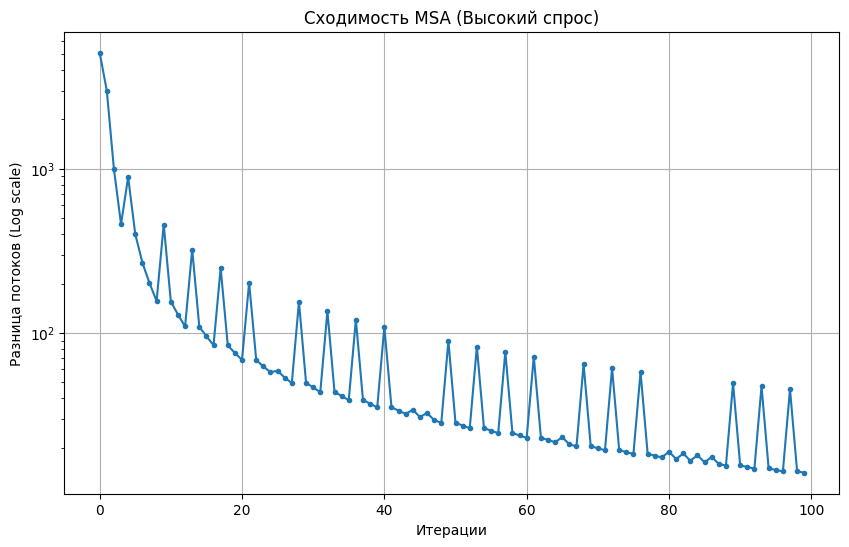

In [ ]:
history = run_high_load_experiment(max_iter=100)

plt.figure(figsize=(10, 6))
plt.plot(history, marker='.', linestyle='-')
plt.title('Сходимость MSA (Высокий спрос)')
plt.xlabel('Итерации')
plt.ylabel('Разница потоков (Log scale)')
plt.yscale('log')
plt.grid(True)
plt.show()

## Итого
График демонстрирует успешную сходимость алгоритма MSA к пользовательскому равновесию в условиях высокого спроса. Наблюдается четкий нисходящий тренд метрики разницы потоков (мы смотрим все в логарифмическом масштабе), которая падает с начального значения около 5000 до 15.6 к 90-й итерации, что подтверждает нахождение стабильного решения. Колебания отражают реакцию алгоритма на перегрузку сети: возникновение пробок заставляет резко перебрасывать потоки на альтернативные маршруты, после чего механизм усреденения сглаживает эти изменения, приводя систему к состоянию где ни один водитель больше не может улучшить свое врмя в пути.

**А не обманывает ли нас алгоритм и этот график?**

Теперь предлагаем рассмотреть образовавшуюся проблему: выше критерием остановки и сходимости выступала Евклидова норма (L2). Однако в алгоритме последовательных усреднений (MSA) шаг принудительно уменьшается на 1/k. При больших k шаг становится настолько маленьким что потоки физически не могут сильно измениться даже если мы все еще далеко от равновесия. То есть (у нас в коде если что `diff = norm (new_flows - flows))` `diff` будет маленьким но это не значит, что мы нашли оптимум. Вместо $L2$ нормы предлагаем использовать RGap. Она безразмерная и отвечает на вопрос: «Насколько текущее состояние далекого от идеального равновесия Уордропа?».

$$RGap = \frac{\sum_{a} t_a(x_a) x_a - \sum_{od} d_{od} q_{od}}{\sum_{a} t_a(x_a) x_a}$$

Интуиция:

  $$RGap = \frac{\text{Реальное время всех} - \text{Идеальное время}}{\text{Идеальное время}}$$


Какая суть: Если RGap равен нулю, то никто не может найти маршрут быстрее текущего (то есть выполнено условие равновесия). Если RGap = 0.01, значит в системе есть лишний 1% лишнего времени, которое можно сократить перераспределением

**RGap**

In [ ]:
@jit
def calculate_relative_gap(current_flows, current_costs, od_matrix, dist_matrix):
    """
    Считает относительный разрыв (меру близости к равновесию).
    """
    total_system_travel_time = jnp.dot(current_flows, current_costs)

    total_shortest_path_travel_time = jnp.sum(od_matrix * dist_matrix)

    rgap = (total_system_travel_time - total_shortest_path_travel_time) / (total_shortest_path_travel_time + 1e-10)

    return rgap


Теперь шаг итерации считаем с gap

In [ ]:
def iteration_step_with_gap(flows, iter_k, od_demand):
    costs = calculate_link_costs(flows, T0_TIMES, CAPACITIES, ALPHA, BETA)  # Расчет затрат
    dist_mat = bellman_ford(costs, START_NODES, END_NODES, NUM_NODES) # Поиск кратчайших путей
    target_flows = all_or_nothing_assignment(od_demand, dist_mat, START_NODES, END_NODES, costs) # Распределение AON
    gap = calculate_relative_gap(flows, costs, od_demand, dist_mat)  # Расчет RGap
    step_size = 1.0 / (iter_k + 1)
    new_flows = (1.0 - step_size) * flows + step_size * target_flows
    diff = jnp.linalg.norm(new_flows - flows) # Старая метрика (для сравнения)
    return new_flows, diff, gap

Функция запуска эксперимента с гэп

In [ ]:
def run_experiment_with_gap(od_demand, max_iter=100):
    print(f"эксперимент с расчетом RGap (максимум {max_iter} итераций)")
    current_flows = jnp.zeros(NUM_LINKS)

    history_diff = []
    history_gap = []

    start_time = time.time()

    for k in range(max_iter):
        current_flows, diff, gap = iteration_step_with_gap(current_flows, k, od_demand)

        d_val = float(diff)
        g_val = float(gap)

        history_diff.append(d_val)
        history_gap.append(g_val)

        if k % 10 == 0 or k == max_iter - 1:
            print(f"итерация {k}: Flow Diff = {d_val:.4f} | Rel. Gap = {g_val:.6f}")

    print(f"Время выполнения: {time.time() - start_time:.2f} сек")
    return current_flows, history_diff, history_gap

Посмотрим что получилось

In [ ]:
final_flows, h_diff, h_gap = run_experiment_with_gap(HIGH_DEMAND_OD, max_iter=1000)

эксперимент с расчетом RGap (максимум 1000 итераций)
итерация 0: Flow Diff = 5098.9756 | Rel. Gap = -1.000000
итерация 10: Flow Diff = 155.4406 | Rel. Gap = 0.019761
итерация 20: Flow Diff = 68.4548 | Rel. Gap = 0.003100
итерация 30: Flow Diff = 46.5828 | Rel. Gap = 0.003288
итерация 40: Flow Diff = 108.6697 | Rel. Gap = 0.001522
итерация 50: Flow Diff = 28.4189 | Rel. Gap = 0.003441
итерация 60: Flow Diff = 22.9856 | Rel. Gap = 0.001093
итерация 70: Flow Diff = 19.8594 | Rel. Gap = 0.001450
итерация 80: Flow Diff = 18.9562 | Rel. Gap = 0.000553
итерация 90: Flow Diff = 15.6104 | Rel. Gap = 0.001932
итерация 100: Flow Diff = 13.8127 | Rel. Gap = 0.000704
итерация 110: Flow Diff = 12.6194 | Rel. Gap = 0.000964
итерация 120: Flow Diff = 12.6755 | Rel. Gap = 0.000231
итерация 130: Flow Diff = 10.7593 | Rel. Gap = 0.001367
итерация 140: Flow Diff = 9.8729 | Rel. Gap = 0.000539
итерация 150: Flow Diff = 9.2479 | Rel. Gap = 0.000739
итерация 160: Flow Diff = 9.5210 | Rel. Gap = 0.000071
итер

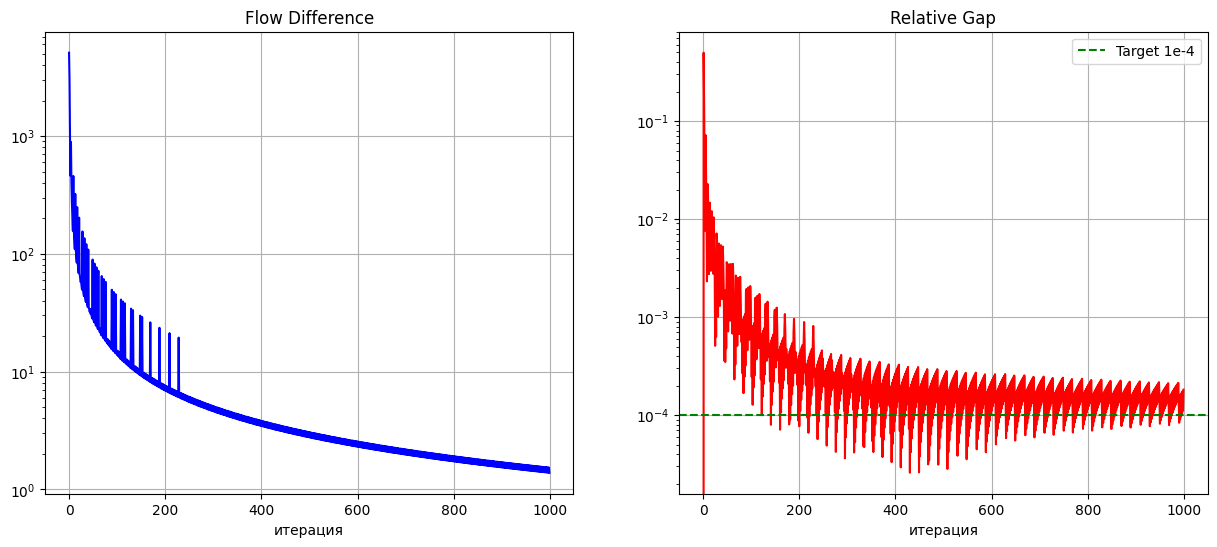

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
ax1.plot(h_diff, 'b-')
ax1.set_title('Flow Difference')
ax1.set_yscale('log')
ax1.set_xlabel('итерация')
ax1.grid(True)

ax2.plot(h_gap, 'r-')
ax2.set_title('Relative Gap')
ax2.set_yscale('log')
ax2.set_xlabel('итерация')
ax2.grid(True)

ax2.axhline(y=1e-4, color='g', linestyle='--', label='Target 1e-4')
ax2.legend()

plt.show()

Напомним на всякий случай что здесь что:

- Flow Difference: Это разница потоков. Показывает Евклидову норму разницы между векторами потоков на текущей и предыдущей итерации. И как говорилось выше, проблема данной метрики, что даже при ее падении до нуля, это не означает сходимость, все упирается в шаг алгоритма

- Relative Gap (RGap): относительный разрыв. Показывает долю лишнего времени, которое тратят водители в системе по сравнению с индвидуальным равновесием.

Интуитивная формула следующая:

$$RGap = \frac{\text{Реальное время всех} - \text{Идеальное время}}{\text{Идеальное время}}$$

##Преимущества RGap:

1) Надежный критерий остановки: RGap < ε гарантирует ε-оптимальность

2) Практический смысл: "Мы улучшим систему на X%"

3) Устойчивость: Не зависит от масштаба сети


##Ограничения RGap:

1) Вычислительная стоимость: Требует расчета dist_matrix на каждой итерации

2) Память: Нужно хранить матрицу расстояний O(N²)


Данная метрика нам говорит насколько мы далеки от принципа Уордропа.



На графике справа есть зеленая линия - это индустриальный стандарт (достичь $10^{-4} $ то есть суммарные потери времени в системе все на 0.01% выше идеальных)

##Анализ графиков:

График Flow Difference как и до этого показывает что изменения становятся меньше, тренд нисходящий, кажется что алгоритм сходится.

Однако RGap показывает нам правду и отвечает на вопрос который мы ставили выше: Да, синий график нас обманывал - алгоритм не сошелся к требуемой точности.

Почему график RGap сильно скачет? Это уже проблема метода MSA, который мы использовали выше. Наш шаг сейчас слепой 1/k он уменьшается слишком быстро и иногда не вовремя, из-за чего алгоритм не может нащупать дно целовой функции

Нам нужен более умный способ выбора шага вместо того чтобы слепо брать шаг 1/k. Как вычислить оптимальный размер шага?

##Алгоритм Франка-Вульфа:

Итак MSA это слепой спуск - постоянное уменьшение шага неоптимально, можем не дойти до минимума (или его малой окресности)

Что делает Алгоритм Франка-Вульфа:

- Мы находим кратчайшие пути и смотрим куда бы поехали машины
 если бы они были умными (как и раньше, мы так уже делали)

- Вместо простого смешения текущего потока x и нового y с коэфом 1/k, алгоритм решает задачу: какой коэф смешивания $\lambda$ от (0 до 1) даст минимальное значение общей загруженности сети (т.е. функции Бекмана).

##Основная идея:

1) Линеаризовать целевую функцию в текущей точке
2) Решить упрощенную линейную задачу (это быстро)
3) Двигаться в направлении решения линейной задачи
4) Выбрать оптимальный шаг (линейный поиск)

**функция лин поиска**

In [ ]:
@jit
def get_bpr_costs(flow, t0, caps, alpha, beta):
    return t0 * (1.0 + alpha * jnp.power(flow / caps, beta))

@jit
def bisection_search(current_x, target_y, t0, caps, alpha, beta):
    """
    Ищет оптимальный шаг lambda (step_size), который минимизирует функцию Бекмана
    вдоль направления (target_y - current_x).
    Использует метод бисекции для поиска нуля производной
    """

    d = target_y - current_x


    low = 0.0
    high = 1.0

    def body_fun(i, val):
        l, h = val
        mid = (l + h) / 2.0
        flow_probe = current_x + mid * d
        cost_probe = get_bpr_costs(flow_probe, t0, caps, alpha, beta)
        derivative = jnp.dot(cost_probe, d)
        new_l = jnp.where(derivative < 0, mid, l)
        new_h = jnp.where(derivative < 0, h, mid)

        return (new_l, new_h)

    final_l, final_h = lax.fori_loop(0, 60, body_fun, (low, high))

    return (final_l + final_h) / 2.0

**Итерация Франка-Вульфа**

In [ ]:
@jit
def iteration_step_fw(flows, od_demand):
    costs = calculate_link_costs(flows, T0_TIMES, CAPACITIES, ALPHA, BETA) # Расчет затрат (градиента)
    dist_mat = bellman_ford(costs, START_NODES, END_NODES, NUM_NODES) # Поиск направления спуска (решение линейной задачи)
    target_flows = all_or_nothing_assignment(od_demand, dist_mat, START_NODES, END_NODES, costs) # target_flows - решение линейной задачи
    step_size = bisection_search(flows, target_flows, T0_TIMES, CAPACITIES, ALPHA, BETA) # Линейный поиск оптимального шага
    new_flows = flows + step_size * (target_flows - flows) # Обновление потоков (не такое как в MSA)
    gap = calculate_relative_gap(flows, costs, od_demand, dist_mat)
    diff = jnp.linalg.norm(new_flows - flows)

    return new_flows, diff, gap

Эксперимент

In [ ]:
def run_fw_experiment(od_demand, max_iter=100):
    print(f"Запуск франк вульфа ({max_iter} итераций")
    current_flows = jnp.zeros(NUM_LINKS)

    history_gap = []

    start_time = time.time()

    for k in range(max_iter):
        current_flows, diff, gap = iteration_step_fw(current_flows, od_demand)

        g_val = float(gap)
        history_gap.append(g_val)

        if k % 10 == 0 or k == max_iter - 1:
            print(f"итерация {k}: Rel. Gap = {g_val:.8f}")

    print(f"Время выполнения: {time.time() - start_time:.2f} сек")
    return current_flows, history_gap

In [ ]:
fw_flows, fw_gap = run_fw_experiment(HIGH_DEMAND_OD, max_iter=10000)

Запуск франк вульфа (10000 итераций
итерация 0: Rel. Gap = -1.00000000
итерация 10: Rel. Gap = -1.00000000
итерация 20: Rel. Gap = -1.00000000
итерация 30: Rel. Gap = -1.00000000
итерация 40: Rel. Gap = -1.00000000
итерация 50: Rel. Gap = -1.00000000
итерация 60: Rel. Gap = -1.00000000
итерация 70: Rel. Gap = -1.00000000
итерация 80: Rel. Gap = -1.00000000
итерация 90: Rel. Gap = -1.00000000
итерация 100: Rel. Gap = -1.00000000
итерация 110: Rel. Gap = -1.00000000
итерация 120: Rel. Gap = -1.00000000
итерация 130: Rel. Gap = -1.00000000
итерация 140: Rel. Gap = -1.00000000
итерация 150: Rel. Gap = -1.00000000
итерация 160: Rel. Gap = -1.00000000
итерация 170: Rel. Gap = -1.00000000
итерация 180: Rel. Gap = -1.00000000
итерация 190: Rel. Gap = -1.00000000
итерация 200: Rel. Gap = -1.00000000
итерация 210: Rel. Gap = -1.00000000
итерация 220: Rel. Gap = -1.00000000
итерация 230: Rel. Gap = -1.00000000
итерация 240: Rel. Gap = -1.00000000
итерация 250: Rel. Gap = -1.00000000
итерация 260:

График

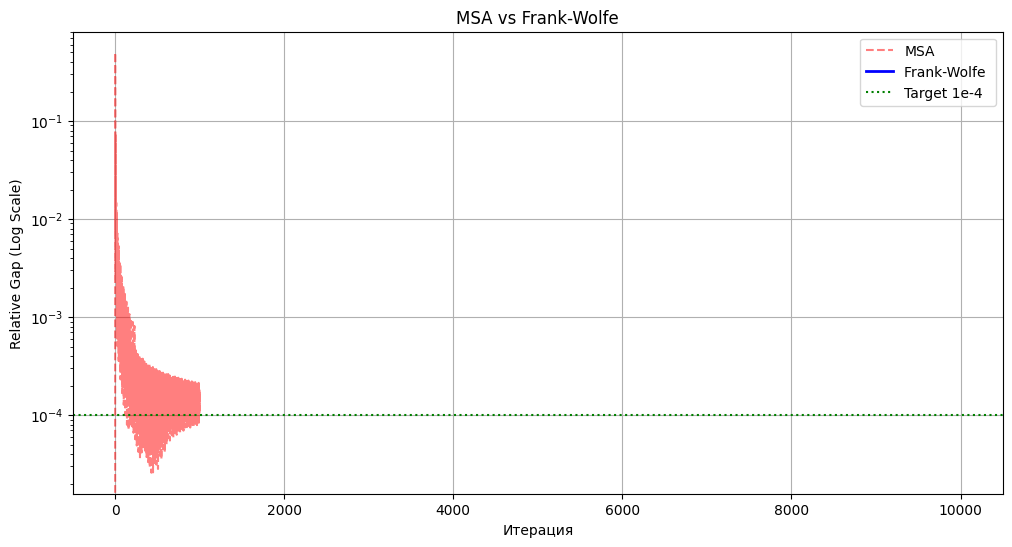

In [ ]:
plt.figure(figsize=(12, 6))

if 'h_gap' in locals():
    plt.plot(h_gap, 'r--', alpha=0.5, label='MSA')

plt.plot(fw_gap, 'b-', linewidth=2, label='Frank-Wolfe ')

plt.axhline(y=1e-4, color='g', linestyle=':', label='Target 1e-4')

plt.title('MSA vs Frank-Wolfe')
plt.xlabel('Итерация')
plt.ylabel('Relative Gap (Log Scale)')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

Получили несходимость FW...

$Gap = \frac{TSTT - SPTT}{SPTT}$

Если Gap = -1, то TSTT приблительно равен нулю - то есть в системе нет машин. Потоки на дорогах равны нулю. Так получилось потому что алгоритм ФВ очень чувствителен к стартовой точке, а мы инициализировали потоки нулями, что по сути является недопустимым состоянием для FW.

In [ ]:
def run_fw_experiment_f(od_demand, max_iter=100):
    t0_costs = calculate_link_costs(jnp.zeros(NUM_LINKS), T0_TIMES, CAPACITIES, ALPHA, BETA)
    dist_mat = bellman_ford(t0_costs, START_NODES, END_NODES, NUM_NODES)
    current_flows = all_or_nothing_assignment(od_demand, dist_mat, START_NODES, END_NODES, t0_costs)

    history_gap = []

    start_time = time.time()

    for k in range(max_iter):
        current_flows, diff, gap = iteration_step_fw(current_flows, od_demand)

        g_val = float(gap)
        history_gap.append(g_val)

        if k % 10 == 0 or k == max_iter - 1:
            print(f"итерация {k}: Rel. Gap = {g_val:.8f}")

    print(f"Время выполнения: {time.time() - start_time:.2f} сек")
    return current_flows, history_gap

Насильно закинули первое поколение машин на дороги (отправили всех по пустым дорогам)

In [ ]:
fw_flows, fw_gap = run_fw_experiment_f(HIGH_DEMAND_OD, max_iter=1000)

итерация 0: Rel. Gap = 0.49738533
итерация 10: Rel. Gap = 0.01123887
итерация 20: Rel. Gap = 0.00822524
итерация 30: Rel. Gap = 0.00649234
итерация 40: Rel. Gap = 0.00536516
итерация 50: Rel. Gap = 0.00457275
итерация 60: Rel. Gap = 0.00398498
итерация 70: Rel. Gap = 0.00353152
итерация 80: Rel. Gap = 0.00317097
итерация 90: Rel. Gap = 0.00287740
итерация 100: Rel. Gap = 0.00263369
итерация 110: Rel. Gap = 0.00242813
итерация 120: Rel. Gap = 0.00225240
итерация 130: Rel. Gap = 0.00210043
итерация 140: Rel. Gap = 0.00196771
итерация 150: Rel. Gap = 0.00185079
итерация 160: Rel. Gap = 0.00174086
итерация 170: Rel. Gap = 0.00050833
итерация 180: Rel. Gap = 0.00070212
итерация 190: Rel. Gap = 0.00146896
итерация 200: Rel. Gap = 0.00043301
итерация 210: Rel. Gap = 0.00060238
итерация 220: Rel. Gap = 0.00127065
итерация 230: Rel. Gap = 0.00037717
итерация 240: Rel. Gap = 0.00052749
итерация 250: Rel. Gap = 0.00111958
итерация 260: Rel. Gap = 0.00033410
итерация 270: Rel. Gap = 0.00046919
ите

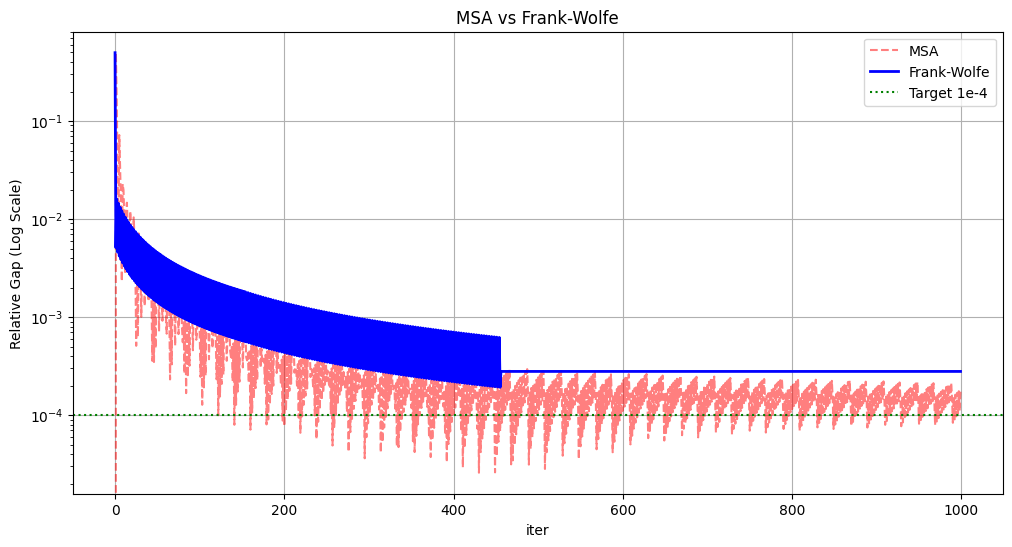

In [ ]:
plt.figure(figsize=(12, 6))
if 'h_gap' in locals():
    plt.plot(h_gap, 'r--', alpha=0.5, label='MSA')
plt.plot(fw_gap, 'b-', linewidth=2, label='Frank-Wolfe')
plt.axhline(y=1e-4, color='g', linestyle=':', label='Target 1e-4')
plt.title('MSA vs Frank-Wolfe')
plt.xlabel('iter')
plt.ylabel('Relative Gap (Log Scale)')
plt.yscale('log')
plt.legend()
plt.grid(True)
plt.show()

тут проблема машинной точности (флоат32 вместо флоат64)

Построим граф сети Sioux Falls

In [ ]:
# @title
!pip install networkx matplotlib

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np

In [ ]:
SIOUX_FALLS_COORDS = {
    0: (50000, 510000), 1: (320000, 510000), 2: (50000, 440000), 3: (130000, 440000),
    4: (320000, 440000), 5: (410000, 440000), 6: (210000, 380000), 7: (320000, 380000),
    8: (50000, 320000), 9: (190000, 320000), 10: (210000, 320000), 11: (50000, 260000),
    12: (110000, 260000), 13: (210000, 260000), 14: (320000, 260000), 15: (110000, 190000),
    16: (210000, 190000), 17: (320000, 190000), 18: (110000, 130000), 19: (320000, 130000),
    20: (210000, 70000), 21: (320000, 70000), 22: (210000, 10000), 23: (320000, 10000)
}

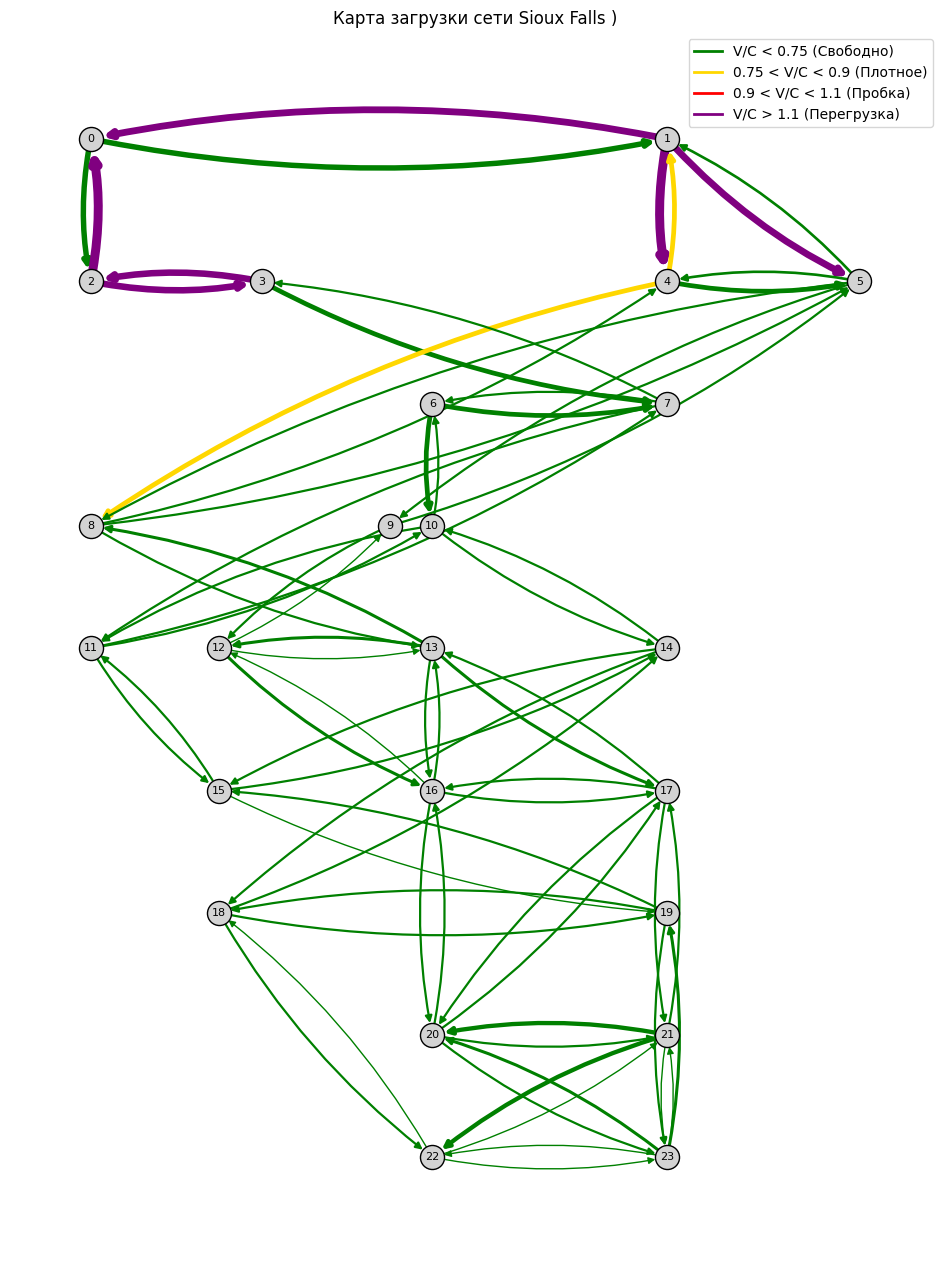

In [ ]:
def plot_network_congestion(flows, capacities, start_nodes, end_nodes):
    G = nx.DiGraph()

    G.add_nodes_from(SIOUX_FALLS_COORDS.keys())

    colors = []
    widths = []

    flows_np = np.array(flows)
    caps_np = np.array(capacities)

    for i in range(len(start_nodes)):
        u = int(start_nodes[i])
        v = int(end_nodes[i])
        flow = flows_np[i]
        cap = caps_np[i]

        vc_ratio = flow / cap

        G.add_edge(u, v)

        if vc_ratio < 0.75:
            col = 'green'
        elif vc_ratio < 0.90:
            col = '#FFD700'
        elif vc_ratio < 1.1:
            col = 'red'
        else:
            col = 'purple'

        colors.append(col)

        w = 1.0 + (flow / 2000.0) * 6.0
        widths.append(w)

    plt.figure(figsize=(12, 16))

    nx.draw_networkx_nodes(G, SIOUX_FALLS_COORDS, node_size=300, node_color='lightgrey', edgecolors='black')
    nx.draw_networkx_labels(G, SIOUX_FALLS_COORDS, font_size=8)

    nx.draw_networkx_edges(G, SIOUX_FALLS_COORDS,
                           edge_color=colors,
                           width=widths,
                           arrowstyle='-|>', arrowsize=10,
                           connectionstyle='arc3, rad=0.1')


    from matplotlib.lines import Line2D
    legend_elements = [
        Line2D([0], [0], color='green', lw=2, label='V/C < 0.75 (Свободно)'),
        Line2D([0], [0], color='#FFD700', lw=2, label='0.75 < V/C < 0.9 (Плотное)'),
        Line2D([0], [0], color='red', lw=2, label='0.9 < V/C < 1.1 (Пробка)'),
        Line2D([0], [0], color='purple', lw=2, label='V/C > 1.1 (Перегрузка)')
    ]
    plt.legend(handles=legend_elements, loc='upper right')

    plt.title("Карта загрузки сети Sioux Falls )")
    plt.axis('off')
    plt.show()


if 'fw_flows_64' in locals():
    flows_to_plot = fw_flows_64
else:
    flows_to_plot = final_flows

plot_network_congestion(flows_to_plot, CAPACITIES, START_NODES, END_NODES)

##Заключение

В работе рассмотрена задача распределения транспортных потоков при условии пользовательского равновесия. Мы привели теоретическую формулировку задачи через принципы Уордропа и эквивалентную оптимизационную задачу Бекмана, обсудили условия существования и единственности решения. Были описаны алгоритмы, лежащие в основе численного решения: поиск кратчайших путей (Беллман–Форд), назначение потоков по кратчайшим маршрутам (алгоритм all-or-nothing), итеративные схемы Франка–Вульфа и метод последовательных усреднений(MSA).

Каждый шаг алгоритма был реализован в коде с использованием инструментов автоматического дифференцирования и векторизации (JAX), что позволило эффективно провести вычислительные эксперименты. На примере сети Sioux Falls мы продемонстрировали работу алгоритма: построены графики сходимости, подтверждающие, что оба метода (FW и MSA) сходятся к одному и тому же решению, удовлетворяющему условиям равновесия. Проведена визуализация распределения потоков, выявившая перегруженные участки сети при повышенном спросе.

##Главные выводы:
Пользовательское равновесие может быть вычислено алгоритмически, и при разумных предпосылках оно единственно. Алгоритм Франка–Вульфа обеспечивает надёжную сходимость, хотя и требует многократных итераций для высокой точности; метод MSA проще, но может иметь колебания на последних шагах. Оба метода подтвердили принцип равновесия: в полученном распределении никакое отклонение не улучшит индивидуальные затраты.

Отчёт иллюстрирует, что даже небольшая сеть может демонстрировать интересные эффекты (перегрузка определённых дорог), а развитые алгоритмы позволяют их исследовать. Полученные навыки и код можно масштабировать на более крупные сети. Таким образом, цели работы – разобраться в теории UE, освоить алгоритмы FW/MSA и применить их на практике – были успешно достигнуты.